# Milestone 3 — Storage vs. Reconstruction Error

Quantify the trade-off between image quality and storage.

In [1]:
import sys, pathlib
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Works after downloading/extracting the package, or from the project root in Colab.
project_root = pathlib.Path.cwd()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error, k_for_error
(project_root / "figures").mkdir(exist_ok=True)
photo_path = project_root / "data" / "my_photo.png"
if photo_path.exists():
    P = np.array(Image.open(photo_path).convert("L"), dtype=float)
else:
    P = None
    print("No personal photo yet: add data/my_photo.png before final submission.")

## Storage and ratio

In [2]:
A=data.camera().astype(float);m,n=A.shape
for k in [1,10,50,100,255,256]: print(k,storage(m,n,k),round(compression_ratio(m,n,k),3))
print("Largest k saving values:",(m*n-1)//(m+n+1))
print("Largest k saving float64 bytes against uint8 pixels:",(m*n-1)//(8*(m+n+1)))

1 1025 255.75
10 10250 25.575
50 51250 5.115
100 102500 2.558
255 261375 1.003
256 262400 0.999
Largest k saving values: 255
Largest k saving float64 bytes against uint8 pixels: 31


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


A rank-k factorization stores k(m+n+1) floating-point values; actual bytes can differ.

## Error prediction

In [3]:
s=np.linalg.svd(A,compute_uv=False)
for k in [1,5,20,50,100]:
  Ak=rank_k_approx(A,k)
  print(f"k={k}: measured={rel_error(A,Ak):.4f}, predicted={predicted_error(s,k):.4f}")
print("Energy check",np.isclose(np.linalg.norm(A)**2,np.sum(s**2)))

k=1: measured=0.3604, predicted=0.3604


k=5: measured=0.1720, predicted=0.1720
k=20: measured=0.1012, predicted=0.1012


k=50: measured=0.0636, predicted=0.0636


k=100: measured=0.0393, predicted=0.0393
Energy check True


Eckart–Young predicts best rank-k Frobenius error from discarded singular values.

## Error vs compression figure

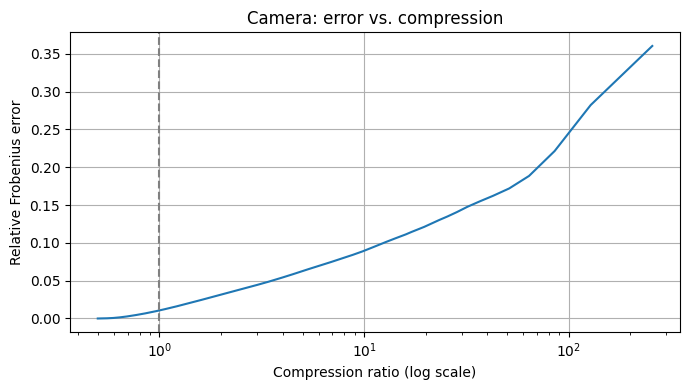

In [4]:
ks=np.arange(1,len(s)+1)
errs=np.array([predicted_error(s,int(k)) for k in ks])
ratios=np.array([compression_ratio(m,n,int(k)) for k in ks])
plt.figure(figsize=(7,4));plt.semilogx(ratios,errs);plt.axvline(1,linestyle="--",color="gray")
plt.xlabel("Compression ratio (log scale)");plt.ylabel("Relative Frobenius error")
plt.title("Camera: error vs. compression");plt.grid(True);plt.tight_layout()
plt.savefig(project_root/"figures"/"error_vs_ratio.png",dpi=150);plt.show()

The dashed line marks the point where factor storage equals pixel-count storage.

## Clipping and personal photograph

In [5]:
A20=rank_k_approx(A,20)
print("Out-of-range pixels",((A20<0)|(A20>255)).sum())
print("Error before and after clipping",rel_error(A,A20),rel_error(A,np.clip(A20,0,255)))
if P is not None:
    sp=np.linalg.svd(P,compute_uv=False)
    print("Personal image shape and k for 10% error",P.shape,k_for_error(sp,0.1))

Out-of-range pixels 2634
Error before and after clipping 0.1012077568277273 0.10083571385013856
Personal image shape and k for 10% error (800, 600) 17


For valid original pixels, clipping an approximation to [0,255] cannot increase per-pixel absolute error. Personal-photo analysis requires the actual asset.

## What we found

**To complete after running:** Record the exact output values from the cells above, explain what they mean in your own words, and check your findings against the assignment instructions.